# Kickstarter outcomes: a Bayesian categorical model

This notebook analyzes `data/truncated_kickstarter_2018.csv`, a 1,000-campaign Kickstarter extract. Each campaign contributes its final `state`, real USD funding goal (`usd_goal_real`), and `main_category`. We retain the three completed states—`failed`, `successful`, and `canceled`—and the available top main categories. Campaigns still `live` or `suspended` are excluded because they do not have one of the modeled final outcomes.

**Question / estimand.** Holding main category fixed, how do the probabilities of failing, succeeding, and being canceled change when a campaign's real USD goal doubles? The analysis is deliberately descriptive-causal: it encodes the proposed causal DAG and estimates this category-adjusted goal-to-outcome relationship. A causal interpretation also needs the assumptions recorded below.

## Causal model and estimand

The proposed DAG is $C \rightarrow G$, $C \rightarrow Y$, and $G \rightarrow Y$, where $C$ is main category, $G$ is the real USD goal, and $Y$ is final state. Category opens the backdoor path $G \leftarrow C \rightarrow Y$; including category in the outcome model blocks that path.

![Causal DAG](category_goal_outcome_dag.svg)

Our estimand is the change in the probabilities of success and cancellation versus failure when a goal doubles, conditional on category. For a causal reading, this requires (among other things) no remaining goal–outcome confounders within category, well-defined hypothetical goal interventions, positivity within categories, and correct model specification. These data alone cannot verify those assumptions.

In [54]:
import os
from pathlib import Path

# Keep PyTensor's compiled modules out of a potentially read-only home directory.
PYTENSOR_CACHE_DIR = Path("/tmp/pytensor-kickstarter")
PYTENSOR_CACHE_DIR.mkdir(parents=True, exist_ok=True)
os.environ["PYTENSOR_FLAGS"] = f"compiledir={PYTENSOR_CACHE_DIR}"

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)
plt.rcParams.update({"axes.grid": True, "font.size": 11})

DATA_PATH = Path("data/truncated_kickstarter_2018.csv")

## Load and prepare the analytic data

We take the ten most frequent `main_category` values in the supplied data, then retain campaigns with a positive `usd_goal_real` and one of the three modeled states. If fewer than ten categories occur, all available categories are retained. $G_0$ is the geometric mean goal in this analytic sample, making $\log_2(G/G_0)=0$ a typical goal.

In [55]:
raw = pd.read_csv(DATA_PATH)
required = {"state", "usd_goal_real", "main_category"}
missing = required.difference(raw.columns)
assert not missing, f"Missing required columns: {missing}"

states = ["failed", "successful", "canceled"]
nonfailure_states = ["successful", "canceled"]
top_categories = raw["main_category"].value_counts().head(10).index

analysis = (
    raw.loc[
        raw["main_category"].isin(top_categories)
        & raw["state"].isin(states)
        & raw["usd_goal_real"].notna()
        & raw["usd_goal_real"].gt(0),
        ["state", "usd_goal_real", "main_category"],
    ]
    .copy()
)

# A stable order makes the category coefficients and plots reproducible.
categories = analysis["main_category"].value_counts().index.tolist()
analysis["main_category"] = pd.Categorical(
    analysis["main_category"], categories=categories, ordered=True
)
analysis["y"] = pd.Categorical(analysis["state"], categories=states).codes
analysis["category_idx"] = analysis["main_category"].cat.codes

# Preserve the original USD amount and create an explicit base-2 log-scale version.
analysis["log2_usd_goal"] = np.log2(analysis["usd_goal_real"])
G0 = np.exp(np.log(analysis["usd_goal_real"]).mean())
analysis["log2_goal_ratio"] = analysis["log2_usd_goal"] - np.log2(G0)

display(analysis[["state", "usd_goal_real", "log2_usd_goal", "main_category", "log2_goal_ratio"]].head())
print(f"Analytic campaigns: {len(analysis):,}")
print(f"Categories retained: {len(categories)} — {', '.join(categories)}")
print(f"Geometric-mean baseline G0: ${G0:,.0f}")
pd.crosstab(analysis["main_category"], analysis["state"], margins=True)

,state,usd_goal_real,log2_usd_goal,main_category,log2_goal_ratio
0,canceled,12000.0,13.550747,Design,0.741904
1,canceled,11900.0,13.538674,Design,0.729831
2,canceled,13500.0,13.720672,Design,0.911829
3,canceled,8500.0,13.053247,Design,0.244405
4,canceled,50000.0,15.609640,Design,2.800798


Analytic campaigns: 994
Categories retained: 7 — Film & Video, Games, Design, Music, Food, Publishing, Fashion
Geometric-mean baseline G0: $7,175


state,canceled,failed,successful,All
main_category,,,,
Film & Video,26,155,131,312
Games,30,74,74,178
Design,22,77,57,156
Music,6,50,56,112
Food,8,57,29,94
Publishing,8,48,19,75
Fashion,7,42,18,67
All,107,503,384,994


## Descriptive summary and distribution checks

The tables report the requested sample size and distributional summaries. Raw USD goals are generally right-skewed, so the model uses the base-2 log scale; the next figure shows the outcome distribution and the log-goal distributions within category.

In [56]:
goal_summary = (
    analysis[["usd_goal_real", "log2_usd_goal"]]
    .agg(["count", "min", "max", "mean", "median", "std"])
    .T
    .rename_axis("variable")
)
display(goal_summary)

outcome_summary = analysis["state"].value_counts().reindex(states).to_frame("campaigns")
outcome_summary["proportion"] = outcome_summary["campaigns"] / len(analysis)
display(outcome_summary)

category_summary = analysis["main_category"].value_counts().reindex(categories).to_frame("campaigns")
display(category_summary)

,count,min,max,mean,median,std
variable,,,,,,
usd_goal_real,994.0,1.0,5.000000e+06,36678.767767,7500.000000,215240.121039
log2_usd_goal,994.0,0.0,2.225350e+01,12.808842,12.872675,2.347576


,campaigns,proportion
state,,
failed,503,0.506036
successful,384,0.386318
canceled,107,0.107646


,campaigns
main_category,
Film & Video,312
Games,178
Design,156
Music,112
Food,94
Publishing,75
Fashion,67


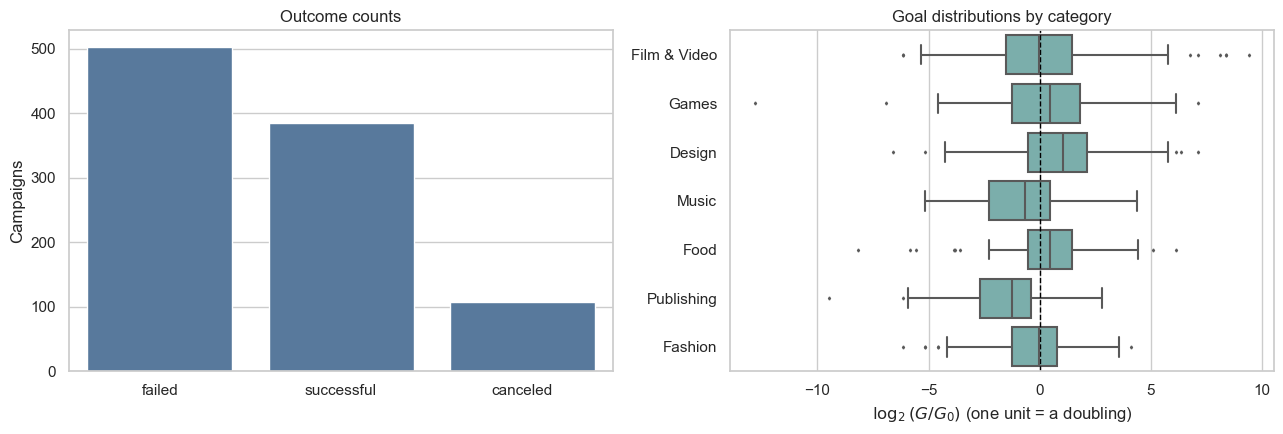

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

analysis["state"].value_counts().reindex(states).plot.bar(
    ax=axes[0], color="#4c78a8", rot=0
)
axes[0].set(title="Outcome counts", xlabel="", ylabel="Campaigns")

goal_groups = [
    analysis.loc[analysis["main_category"] == category, "log2_goal_ratio"].to_numpy()
    for category in categories
]
boxplot = axes[1].boxplot(
    goal_groups, vert=False, labels=categories, patch_artist=True, flierprops={"markersize": 1.5}
)
for box in boxplot["boxes"]:
    box.set_facecolor("#72b7b2")
axes[1].axvline(0, color="black", lw=1, ls="--")
axes[1].set(
    title="Goal distributions by category",
    xlabel=r"$\log_2(G/G_0)$ (one unit = a doubling)",
    ylabel="",
)
plt.tight_layout()

## Statistical model and priors

Failure is the reference outcome. For campaign $i$ in category $c_i$, let $x_i=\log_2(G_i/G_0)$. We model:

$$Y_i \sim \operatorname{Categorical}(\boldsymbol\pi_i),\qquad
\boldsymbol\pi_i = \operatorname{softmax}(0,\eta_{i,s},\eta_{i,c})$$

$$\eta_{i,k}=a_k+b_k x_i+u_{c_i,k},\quad k\in\{s=\text{successful},c=\text{canceled}\}.$$

### Prior rationale

The intercept priors do **not** use outcome frequencies from this dataset. Kickstarter's published historical statistics reported an overall funding success rate near 44% ([Kickstarter, 2013](https://www.kickstarter.com/blog/five-million-backers)). We encode a broad baseline split of roughly 52% failed, 44% successful, and 4% canceled with $a_s\sim\operatorname{Normal}(-0.17,1)$ and $a_c\sim\operatorname{Normal}(-2.56,1)$. The cancellation location is deliberately low because cancellation is expected to be a minority terminal state; the standard deviation of 1 makes this assumption weak enough to be substantially revised by the data.

Goal coefficients use $b_k\sim\operatorname{Normal}(0,0.5)$. Because one unit of $x_i$ is a doubling of the goal, this assigns most prior mass to odds ratios of roughly 0.45–2.23 for a doubling (the central 89% interval): wide enough for material effects, but skeptical of extreme changes. Category adjustments use $u_{c,k}\sim\operatorname{Normal}(0,0.5)$ before sum-to-zero centering, allowing meaningful category differences while regularizing the smaller categories. Failure is the softmax reference ($\eta_{i,fail}=0$), so it has no redundant separately estimated coefficient; its probability is nevertheless calculated and shown with the other two outcomes.

In [58]:
coords = {
    "campaign": np.arange(len(analysis)),
    "category": categories,
    "outcome": states,
    "nonfailure_outcome": nonfailure_states,
}

with pm.Model(coords=coords) as categorical_model:
    x = pm.MutableData("log2_goal_ratio", analysis["log2_goal_ratio"].to_numpy(), dims="campaign")
    c_idx = pm.MutableData("category_idx", analysis["category_idx"].to_numpy(), dims="campaign")

    # These locations were elicited before inspecting this dataset's outcomes.
    alpha = pm.Normal(
        "alpha", mu=np.array([-0.17, -2.56]), sigma=1.0, dims="nonfailure_outcome"
    )
    beta_goal = pm.Normal(
        "beta_goal", mu=0.0, sigma=0.5, dims="nonfailure_outcome"
    )
    category_raw = pm.Normal(
        "category_raw", mu=0.0, sigma=0.5,
        dims=("category", "nonfailure_outcome"),
    )
    category_effect = pm.Deterministic(
        "category_effect",
        category_raw - pt.mean(category_raw, axis=0, keepdims=True),
        dims=("category", "nonfailure_outcome"),
    )

    eta_nonfailure = alpha + beta_goal * x[:, None] + category_effect[c_idx]
    eta = pt.concatenate([pt.zeros((x.shape[0], 1)), eta_nonfailure], axis=1)
    p = pm.Deterministic("p", pm.math.softmax(eta, axis=1), dims=("campaign", "outcome"))
    # This derived probability vector exposes all three outcomes, including failure,
    # for an average category at the geometric-mean goal (x = 0).
    p_at_G0_average_category = pm.Deterministic(
        "p_at_G0_average_category",
        pm.math.softmax(pt.concatenate([pt.zeros(1), alpha]), axis=0),
        dims="outcome",
    )
    y = pm.Categorical("y", p=p, observed=analysis["y"].to_numpy(), dims="campaign")

    prior_predictive = pm.sample_prior_predictive(samples=1_000, random_seed=RANDOM_SEED)

categorical_model

Sampling: [alpha, beta_goal, category_raw, y]


                   alpha ~ Normal(<constant>, 1)
               beta_goal ~ Normal(0, 0.5)
            category_raw ~ Normal(0, 0.5)
         category_effect ~ Deterministic(f(category_raw))
                       p ~ Deterministic(f(alpha, category_raw, beta_goal))
p_at_G0_average_category ~ Deterministic(f(alpha))
                       y ~ Categorical(p)

`alpha`, `beta_goal`, and `category_effect` are the primary parameters. A positive `beta_goal[successful]`, for example, means that doubling the goal increases the log-odds of success relative to failure after category adjustment. Inspect the priors before seeing posterior estimates; revise them if they imply implausible outcome probabilities.

,mean,sd,hdi_5.5%,hdi_94.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha[successful],-0.141,1.042,-1.770,1.478,0.034,0.026,967.0,761.0,NaN
alpha[canceled],-2.561,0.998,-4.086,-0.902,0.031,0.022,1012.0,1067.0,NaN
beta_goal[successful],-0.042,0.494,-0.835,0.723,0.016,0.011,946.0,982.0,NaN
beta_goal[canceled],-0.007,0.500,-0.715,0.864,0.017,0.012,816.0,944.0,NaN
"category_raw[Film & Video, successful]",0.022,0.511,-0.885,0.709,0.016,0.012,991.0,1017.0,NaN
"category_raw[Film & Video, canceled]",0.007,0.499,-0.762,0.760,0.015,0.011,1072.0,944.0,NaN
"category_raw[Games, successful]",-0.002,0.491,-0.809,0.737,0.016,0.012,900.0,859.0,NaN
"category_raw[Games, canceled]",-0.014,0.504,-0.770,0.846,0.017,0.012,924.0,918.0,NaN
"category_raw[Design, successful]",0.020,0.498,-0.770,0.823,0.016,0.011,955.0,978.0,NaN
"category_raw[Design, canceled]",-0.003,0.486,-0.761,0.813,0.015,0.011,1013.0,868.0,NaN


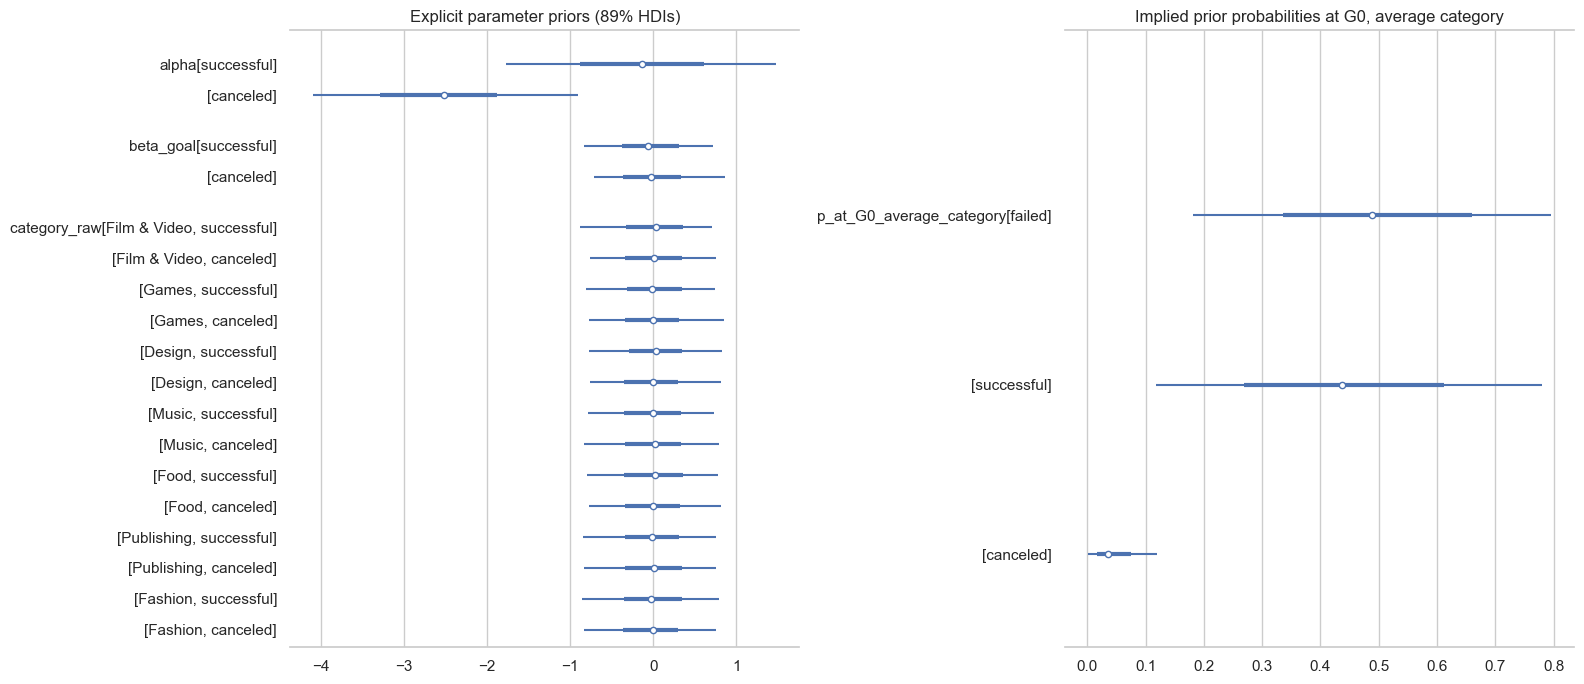

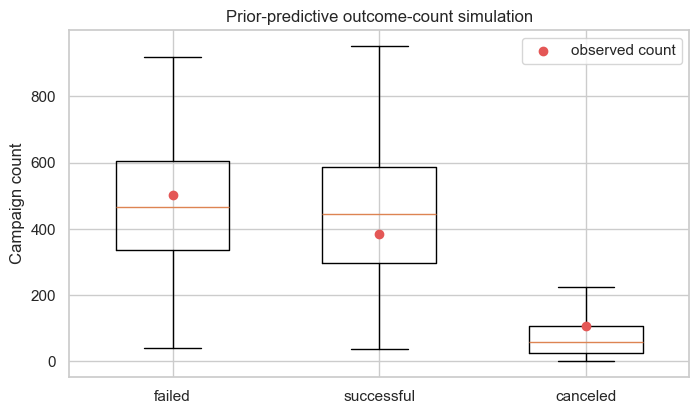

In [59]:
# Every stochastic prior is summarized below. category_raw has one value per
# retained category and non-failure outcome.
prior_parameter_summary = az.summary(
    prior_predictive.prior,
    var_names=["alpha", "beta_goal", "category_raw"],
    hdi_prob=0.89,
)
display(prior_parameter_summary)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
az.plot_forest(
    prior_predictive.prior,
    var_names=["alpha", "beta_goal", "category_raw"],
    combined=True,
    hdi_prob=0.89,
    ax=axes[0],
)
axes[0].set_title("Explicit parameter priors (89% HDIs)")
az.plot_forest(
    prior_predictive.prior,
    var_names=["p_at_G0_average_category"],
    combined=True,
    hdi_prob=0.89,
    ax=axes[1],
)
axes[1].set_title("Implied prior probabilities at G0, average category")
plt.tight_layout()

# Custom prior-predictive check: compare simulated outcome counts with the
# observed counts without using arviz.plot_ppc().
prior_y = prior_predictive.prior_predictive["y"].stack(sample=("chain", "draw")).values
prior_counts = np.stack([
    np.bincount(prior_y[:, draw], minlength=len(states))
    for draw in range(prior_y.shape[1])
])

fig, ax = plt.subplots(figsize=(8, 4.5))
positions = np.arange(len(states))
ax.boxplot(prior_counts, positions=positions, widths=0.55, showfliers=False)
ax.scatter(positions, np.bincount(analysis["y"], minlength=len(states)),
           color="#e45756", zorder=3, label="observed count")
ax.set(xticks=positions, xticklabels=states, ylabel="Campaign count",
       title="Prior-predictive outcome-count simulation")
ax.legend();

## Fit the model

Sampling uses four independent chains. The first run may take a few minutes; reduce `draws` and `tune` for a quick development check, but use sufficiently long chains for final inference.

In [60]:
with categorical_model:
    idata = pm.sample(
        draws=1_000,
        tune=1_000,
        chains=4,
        cores=4,
        target_accept=0.90,
        random_seed=RANDOM_SEED,
        idata_kwargs={"log_likelihood": True},
    )
    posterior_predictive = pm.sample_posterior_predictive(
        idata, random_seed=RANDOM_SEED, extend_inferencedata=True
    )

Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta_goal, category_raw]


<div><progress max="8000" value="8000"></progress> 100.00% [8000/8000 00:11&lt;00:00... Sampling 4 chains, 0 divergences]</div>

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 12 seconds.
Sampling: [y]


<div><progress max="4000" value="4000"></progress> 100.00% [4000/4000 00:10&lt;00:00]</div>

## Why category adjustment matters

For comparison only, the next model deliberately omits category. It is computationally valid but causally inappropriate for the stated estimand because it leaves the backdoor path $G\leftarrow C\rightarrow Y$ open. Its goal coefficients mix the direct goal–outcome relationship with category composition: campaigns in different categories can have both different goals and different outcome probabilities. The adjusted model above is therefore the primary model; the table below quantifies how the unadjusted association changes when the confounder is included.

In [ ]:
# Intentionally incorrect for the causal estimand: category C is omitted.
with pm.Model(coords={"campaign": np.arange(len(analysis)), "outcome": states,
                      "nonfailure_outcome": nonfailure_states}) as unadjusted_model:
    x_unadjusted = pm.MutableData(
        "log2_goal_ratio", analysis["log2_goal_ratio"].to_numpy(), dims="campaign"
    )
    unadjusted_alpha = pm.Normal(
        "unadjusted_alpha", mu=np.array([-0.17, -2.56]), sigma=1.0,
        dims="nonfailure_outcome",
    )
    unadjusted_beta_goal = pm.Normal(
        "unadjusted_beta_goal", mu=0.0, sigma=0.5, dims="nonfailure_outcome"
    )
    unadjusted_eta_nonfailure = unadjusted_alpha + unadjusted_beta_goal * x_unadjusted[:, None]
    unadjusted_eta = pt.concatenate(
        [pt.zeros((x_unadjusted.shape[0], 1)), unadjusted_eta_nonfailure], axis=1
    )
    unadjusted_p = pm.Deterministic(
        "unadjusted_p", pm.math.softmax(unadjusted_eta, axis=1), dims=("campaign", "outcome")
    )
    pm.Categorical("unadjusted_y", p=unadjusted_p, observed=analysis["y"].to_numpy(), dims="campaign")
    unadjusted_idata = pm.sample(
        draws=1_000, tune=1_000, chains=4, cores=4, target_accept=0.90,
        random_seed=RANDOM_SEED + 2,
    )

In [ ]:
comparison_rows = []
for outcome in nonfailure_states:
    adjusted_draws = idata.posterior["beta_goal"].sel(nonfailure_outcome=outcome).values.ravel()
    unadjusted_draws = unadjusted_idata.posterior["unadjusted_beta_goal"].sel(
        nonfailure_outcome=outcome
    ).values.ravel()
    adjusted_hdi = az.hdi(adjusted_draws, hdi_prob=0.89)
    unadjusted_hdi = az.hdi(unadjusted_draws, hdi_prob=0.89)
    comparison_rows.append({
        "outcome vs failed": outcome,
        "adjusted mean": adjusted_draws.mean(),
        "adjusted 89% HDI": f"[{adjusted_hdi[0]:.2f}, {adjusted_hdi[1]:.2f}]",
        "unadjusted mean": unadjusted_draws.mean(),
        "unadjusted 89% HDI": f"[{unadjusted_hdi[0]:.2f}, {unadjusted_hdi[1]:.2f}]",
        "unadjusted − adjusted": unadjusted_draws.mean() - adjusted_draws.mean(),
    })
comparison = pd.DataFrame(comparison_rows).set_index("outcome vs failed")
display(comparison)

fig, ax = plt.subplots(figsize=(8, 3.5))
for outcome_index, outcome in enumerate(nonfailure_states):
    for offset, (label, draws, color) in enumerate([
        ("adjusted", idata.posterior["beta_goal"].sel(nonfailure_outcome=outcome).values.ravel(), "#4c78a8"),
        ("unadjusted", unadjusted_idata.posterior["unadjusted_beta_goal"].sel(nonfailure_outcome=outcome).values.ravel(), "#e45756"),
    ]):
        interval = az.hdi(draws, hdi_prob=0.89)
        y = outcome_index + (offset - 0.5) * 0.25
        ax.errorbar(draws.mean(), y, xerr=[[draws.mean() - interval[0]], [interval[1] - draws.mean()]],
                    fmt="o", color=color, capsize=4, label=label if outcome_index == 0 else None)
ax.axvline(0, color="black", lw=1, ls="--")
ax.set(yticks=np.arange(len(nonfailure_states)), yticklabels=[f"{x} vs failed" for x in nonfailure_states],
       xlabel="Goal coefficient: change in log-odds per goal doubling",
       title="Confound-adjusted versus unadjusted goal effects (89% HDIs)")
ax.legend();

## Diagnostics and posterior checks

Before interpreting effects, check that $\hat R$ is close to 1.00, effective sample sizes are adequate, and there were no divergences. The predictive check below compares observed and replicated outcome counts.

,mean,sd,hdi_5.5%,hdi_94.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha[successful],-0.448,0.081,-0.587,-0.331,0.001,0.001,3673.0,2975.0,1.0
alpha[canceled],-1.680,0.125,-1.875,-1.472,0.002,0.001,3787.0,3299.0,1.0
beta_goal[successful],-0.226,0.033,-0.279,-0.173,0.001,0.000,3868.0,3351.0,1.0
beta_goal[canceled],0.066,0.048,-0.009,0.145,0.001,0.001,3868.0,3021.0,1.0
"category_raw[Film & Video, successful]",0.243,0.223,-0.107,0.600,0.006,0.004,1400.0,2425.0,1.0
"category_raw[Film & Video, canceled]",-0.159,0.273,-0.618,0.258,0.005,0.004,2769.0,2680.0,1.0
"category_raw[Games, successful]",0.392,0.246,0.028,0.804,0.006,0.004,1645.0,2555.0,1.0
"category_raw[Games, canceled]",0.564,0.270,0.121,0.961,0.005,0.004,2830.0,3097.0,1.0
"category_raw[Design, successful]",0.247,0.247,-0.125,0.664,0.006,0.004,1714.0,2660.0,1.0
"category_raw[Design, canceled]",0.246,0.283,-0.197,0.705,0.005,0.004,2791.0,3023.0,1.0


Divergences: 0; maximum R-hat: 1.000


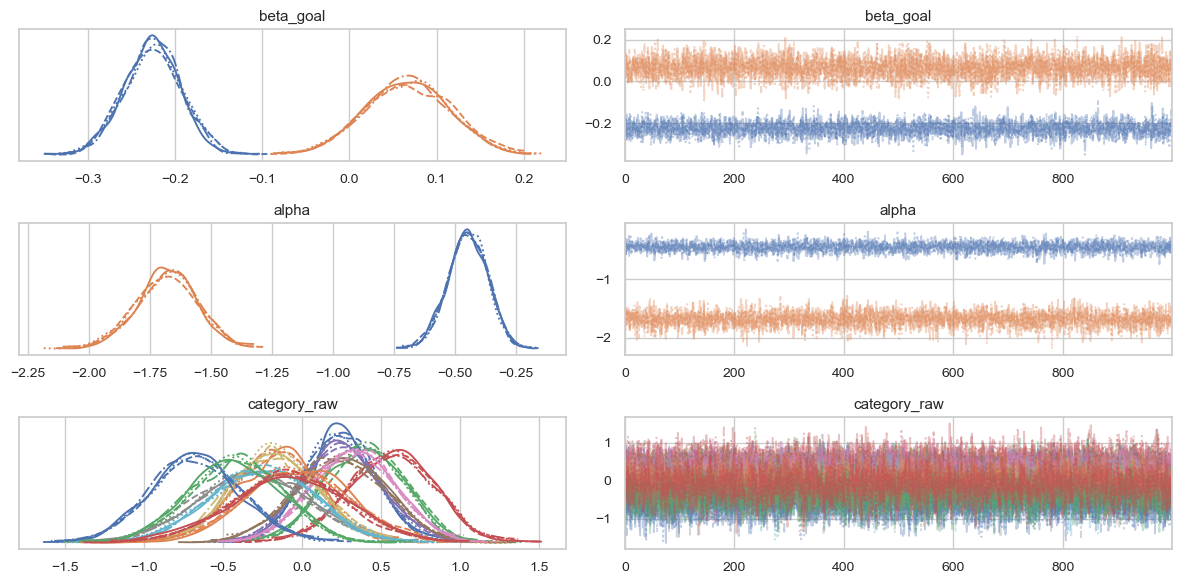

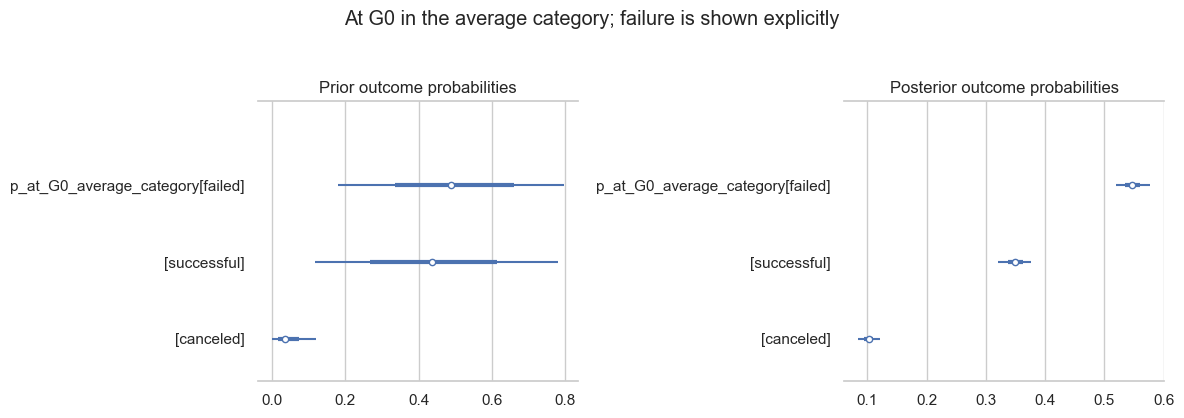

In [61]:
# Posterior summary for every sampled parameter, its centered category effect,
# and the derived three-state probability vector (which includes failure).
summary = az.summary(
    idata,
    var_names=[
        "alpha", "beta_goal", "category_raw", "category_effect",
        "p_at_G0_average_category",
    ],
    hdi_prob=0.89,
)
display(summary)

n_divergent = int(idata.sample_stats["diverging"].sum())
max_rhat = float(summary["r_hat"].max())
print(f"Divergences: {n_divergent}; maximum R-hat: {max_rhat:.3f}")

az.plot_trace(idata, var_names=["beta_goal", "alpha", "category_raw"], compact=True)
plt.tight_layout()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
az.plot_forest(
    prior_predictive.prior, var_names=["p_at_G0_average_category"],
    combined=True, hdi_prob=0.89, ax=axes[0]
)
axes[0].set_title("Prior outcome probabilities")
az.plot_forest(
    idata.posterior, var_names=["p_at_G0_average_category"],
    combined=True, hdi_prob=0.89, ax=axes[1]
)
axes[1].set_title("Posterior outcome probabilities")
fig.suptitle("At G0 in the average category; failure is shown explicitly", y=1.04)
plt.tight_layout()

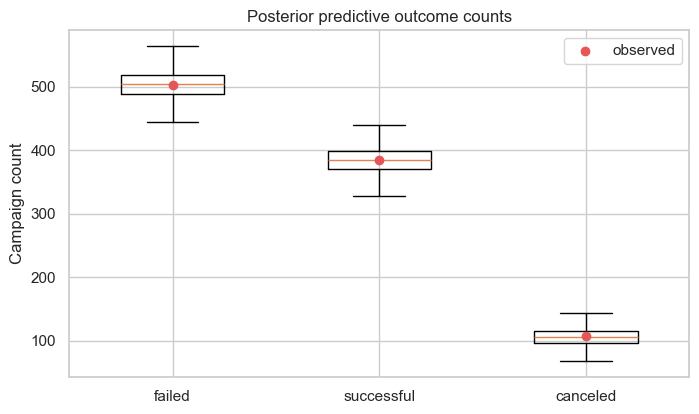

In [62]:
# A custom posterior predictive check. It displays observed counts, uncertainty
# in the posterior expected count, and the wider uncertainty of future replicated counts.
observed_counts = np.bincount(analysis["y"], minlength=len(states))
posterior_p = idata.posterior["p"].stack(sample=("chain", "draw")).transpose(
    "sample", "campaign", "outcome"
).values
expected_count_draws = posterior_p.sum(axis=1)

replicated_y = idata.posterior_predictive["y"].stack(sample=("chain", "draw")).values
replicated_counts = np.stack([
    np.bincount(replicated_y[:, draw], minlength=len(states))
    for draw in range(replicated_y.shape[1])
])

ppc_rows = []
fig, ax = plt.subplots(figsize=(9, 5))
positions = np.arange(len(states))
for state_index, state in enumerate(states):
    expected_hdi = az.hdi(expected_count_draws[:, state_index], hdi_prob=0.89)
    predictive_hdi = az.hdi(replicated_counts[:, state_index], hdi_prob=0.89)
    posterior_mean = expected_count_draws[:, state_index].mean()
    # Thick pale interval = posterior-predictive uncertainty for a new replication.
    ax.vlines(state_index, predictive_hdi[0], predictive_hdi[1], color="#9ecae1", lw=14,
              label="89% posterior-predictive interval" if state_index == 0 else None)
    # Thin dark interval = uncertainty in the posterior mean expected count.
    ax.errorbar(state_index, posterior_mean,
                yerr=[[posterior_mean - expected_hdi[0]], [expected_hdi[1] - posterior_mean]],
                fmt="o", color="#1f4e79", capsize=5,
                label="posterior mean and 89% interval" if state_index == 0 else None)
    ax.scatter(state_index, observed_counts[state_index], marker="D", s=55, color="#e45756",
               zorder=4, label="observed count" if state_index == 0 else None)
    ppc_rows.append({
        "state": state, "observed": observed_counts[state_index],
        "posterior mean expected count": posterior_mean,
        "expected-count 89% HDI": f"[{expected_hdi[0]:.1f}, {expected_hdi[1]:.1f}]",
        "predictive-count 89% HDI": f"[{predictive_hdi[0]:.1f}, {predictive_hdi[1]:.1f}]",
        "observed inside predictive interval": predictive_hdi[0] <= observed_counts[state_index] <= predictive_hdi[1],
    })

ax.set(xticks=positions, xticklabels=states, ylabel="Campaign count",
       title="Posterior predictive outcome-count check")
ax.legend(loc="best")
plt.tight_layout()

ppc_summary = pd.DataFrame(ppc_rows).set_index("state")
display(ppc_summary)

### Posterior-predictive interpretation

Use the displayed `ppc_summary` to assess fit. A satisfactory aggregate check has each observed outcome count inside its posterior-predictive interval and close to the posterior mean expected count. The posterior-predictive interval must be wider than the expected-count interval because it includes both parameter uncertainty and campaign-to-campaign outcome variation. If an observed count falls outside its predictive interval, or is systematically distant from the posterior mean, the categorical model is not reproducing that aspect of the observed outcome distribution and should be expanded or reconsidered. This check is aggregate; the category-specific probability curves later in the notebook provide a complementary conditional check.

## Simulation-based parameter recovery

A model should be able to recover effects when the data-generating values are known. The next cells simulate campaigns from the same categorical-softmax data-generating process with fixed, pre-defined intercepts, goal effects, and category effects. They then fit the same model specification and mark the known truth in each posterior with `ref_val`. This is a validation exercise, not part of the Kickstarter inference.

In [63]:
# Fixed values used only to create simulated data. They are known before fitting.
SIM_N = 1_200
true_alpha = np.array([-0.20, -2.40])
true_beta_goal = np.array([-0.50, 0.25])
true_category_effect = (
    np.linspace(-0.35, 0.35, len(categories))[:, None] * np.array([1.0, -0.60])
)

sim_x = rng.normal(loc=0.0, scale=1.5, size=SIM_N)
sim_category_idx = rng.integers(0, len(categories), size=SIM_N)
sim_eta_nonfailure = (
    true_alpha + sim_x[:, None] * true_beta_goal + true_category_effect[sim_category_idx]
)
sim_eta = np.column_stack([np.zeros(SIM_N), sim_eta_nonfailure])
sim_probability = np.exp(sim_eta - sim_eta.max(axis=1, keepdims=True))
sim_probability /= sim_probability.sum(axis=1, keepdims=True)
sim_y = np.array([rng.choice(len(states), p=p_i) for p_i in sim_probability])

sim_coords = {
    "sim_campaign": np.arange(SIM_N),
    "sim_category": categories,
    "nonfailure_outcome": nonfailure_states,
}
with pm.Model(coords=sim_coords) as recovery_model:
    sim_x_data = pm.MutableData("sim_x", sim_x, dims="sim_campaign")
    sim_c_data = pm.MutableData("sim_category_idx", sim_category_idx, dims="sim_campaign")
    sim_alpha = pm.Normal("sim_alpha", mu=np.array([-0.17, -2.56]), sigma=1.0, dims="nonfailure_outcome")
    sim_beta_goal = pm.Normal("sim_beta_goal", mu=0.0, sigma=0.5, dims="nonfailure_outcome")
    sim_category_raw = pm.Normal(
        "sim_category_raw", mu=0.0, sigma=0.5,
        dims=("sim_category", "nonfailure_outcome"),
    )
    sim_category_effect = pm.Deterministic(
        "sim_category_effect",
        sim_category_raw - pt.mean(sim_category_raw, axis=0, keepdims=True),
        dims=("sim_category", "nonfailure_outcome"),
    )
    sim_eta_nonfailure_model = (
        sim_alpha + sim_beta_goal * sim_x_data[:, None] + sim_category_effect[sim_c_data]
    )
    sim_eta_model = pt.concatenate(
        [pt.zeros((sim_x_data.shape[0], 1)), sim_eta_nonfailure_model], axis=1
    )
    sim_p = pm.math.softmax(sim_eta_model, axis=1)
    pm.Categorical("sim_y", p=sim_p, observed=sim_y, dims="sim_campaign")
    recovery_idata = pm.sample(
        draws=1_000, tune=1_000, chains=4, cores=4, target_accept=0.90,
        random_seed=RANDOM_SEED + 1,
    )

Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sim_alpha, sim_beta_goal, sim_category_raw]


<div><progress max="8000" value="8000"></progress> 100.00% [8000/8000 00:12&lt;00:00... Sampling 4 chains, 0 divergences]</div>

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 12 seconds.


,mean,sd,hdi_5.5%,hdi_94.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
sim_alpha[successful],-0.231,0.066,-0.336,-0.127,0.001,0.001,4071.0,3111.0,1.0
sim_alpha[canceled],-2.287,0.142,-2.509,-2.054,0.002,0.002,3418.0,2995.0,1.0
sim_beta_goal[successful],-0.607,0.049,-0.682,-0.526,0.001,0.001,4223.0,3175.0,1.0
sim_beta_goal[canceled],0.105,0.090,-0.037,0.248,0.001,0.001,3712.0,3082.0,1.0
"sim_category_effect[Film & Video, successful]",-0.108,0.159,-0.355,0.146,0.002,0.002,7945.0,3126.0,1.0
"sim_category_effect[Film & Video, canceled]",0.466,0.239,0.083,0.832,0.003,0.002,7558.0,3207.0,1.0
"sim_category_effect[Games, successful]",-0.124,0.152,-0.363,0.123,0.002,0.002,9519.0,2594.0,1.0
"sim_category_effect[Games, canceled]",0.031,0.245,-0.343,0.448,0.003,0.004,7301.0,3429.0,1.0
"sim_category_effect[Design, successful]",0.024,0.149,-0.202,0.272,0.002,0.003,9751.0,3145.0,1.0
"sim_category_effect[Design, canceled]",0.222,0.245,-0.173,0.594,0.003,0.003,6322.0,3305.0,1.0


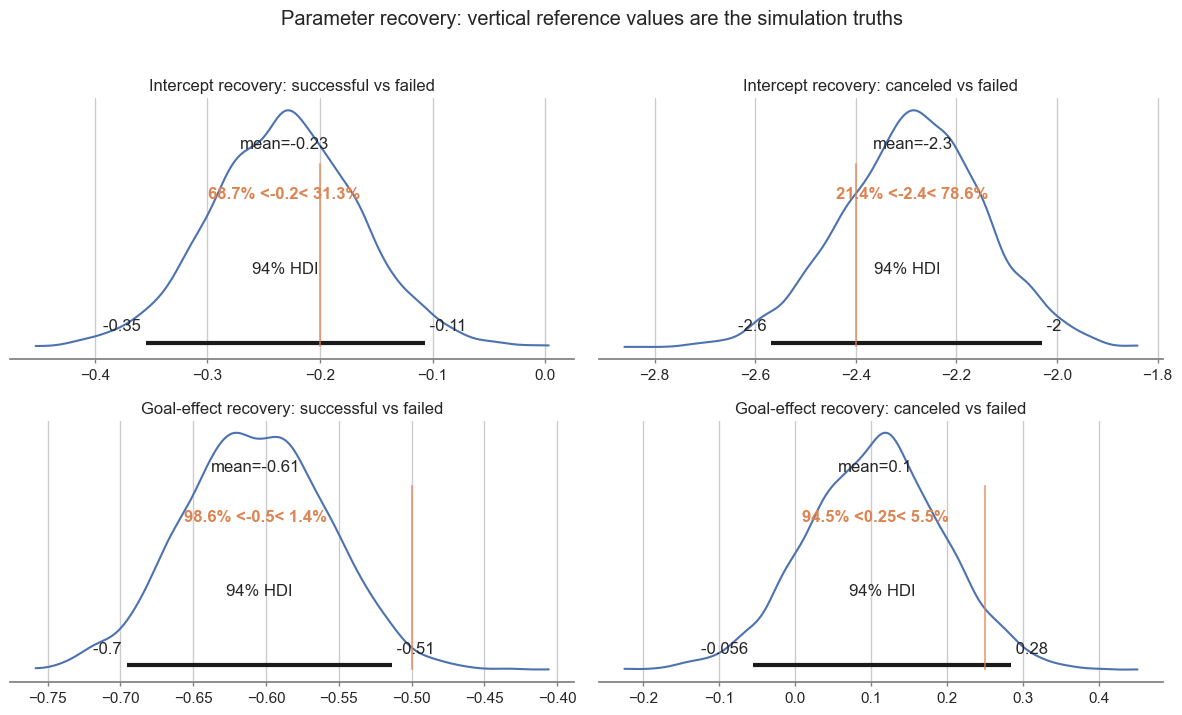

In [64]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for outcome_index, outcome in enumerate(nonfailure_states):
    az.plot_posterior(
        recovery_idata, var_names=["sim_alpha"],
        coords={"nonfailure_outcome": outcome},
        ref_val=true_alpha[outcome_index], ax=axes[0, outcome_index],
    )
    axes[0, outcome_index].set_title(f"Intercept recovery: {outcome} vs failed")
    az.plot_posterior(
        recovery_idata, var_names=["sim_beta_goal"],
        coords={"nonfailure_outcome": outcome},
        ref_val=true_beta_goal[outcome_index], ax=axes[1, outcome_index],
    )
    axes[1, outcome_index].set_title(f"Goal-effect recovery: {outcome} vs failed")
fig.suptitle("Parameter recovery: vertical reference values are the simulation truths", y=1.02)
plt.tight_layout()

recovery_summary = az.summary(
    recovery_idata, var_names=["sim_alpha", "sim_beta_goal", "sim_category_effect"], hdi_prob=0.89
)
display(recovery_summary)

## Interpret the goal effect

Exponentiating each goal coefficient gives the posterior odds ratio for a doubling of the goal, relative to failure. Odds ratios are not probability ratios, so the category-specific probability curves that follow are the clearest way to communicate practical effects.

In [65]:
goal_or = np.exp(idata.posterior["beta_goal"])
goal_or_summary = az.summary(goal_or, hdi_prob=0.89)
goal_or_summary.index = [f"odds ratio: {state} vs failed" for state in nonfailure_states]
display(goal_or_summary)

for outcome in nonfailure_states:
    values = goal_or.sel(nonfailure_outcome=outcome).values.ravel()
    print(
        f"{outcome:10s}: median odds ratio = {np.median(values):.2f}; "
        f"89% HDI = [{az.hdi(values, hdi_prob=0.89)[0]:.2f}, {az.hdi(values, hdi_prob=0.89)[1]:.2f}]"
    )

,mean,sd,hdi_5.5%,hdi_94.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
odds ratio: successful vs failed,0.798,0.026,0.757,0.841,0.000,0.000,3868.0,3351.0,1.0
odds ratio: canceled vs failed,1.070,0.052,0.991,1.156,0.001,0.001,3868.0,3021.0,1.0


successful: median odds ratio = 0.80; 89% HDI = [0.76, 0.84]
canceled  : median odds ratio = 1.07; 89% HDI = [0.99, 1.16]


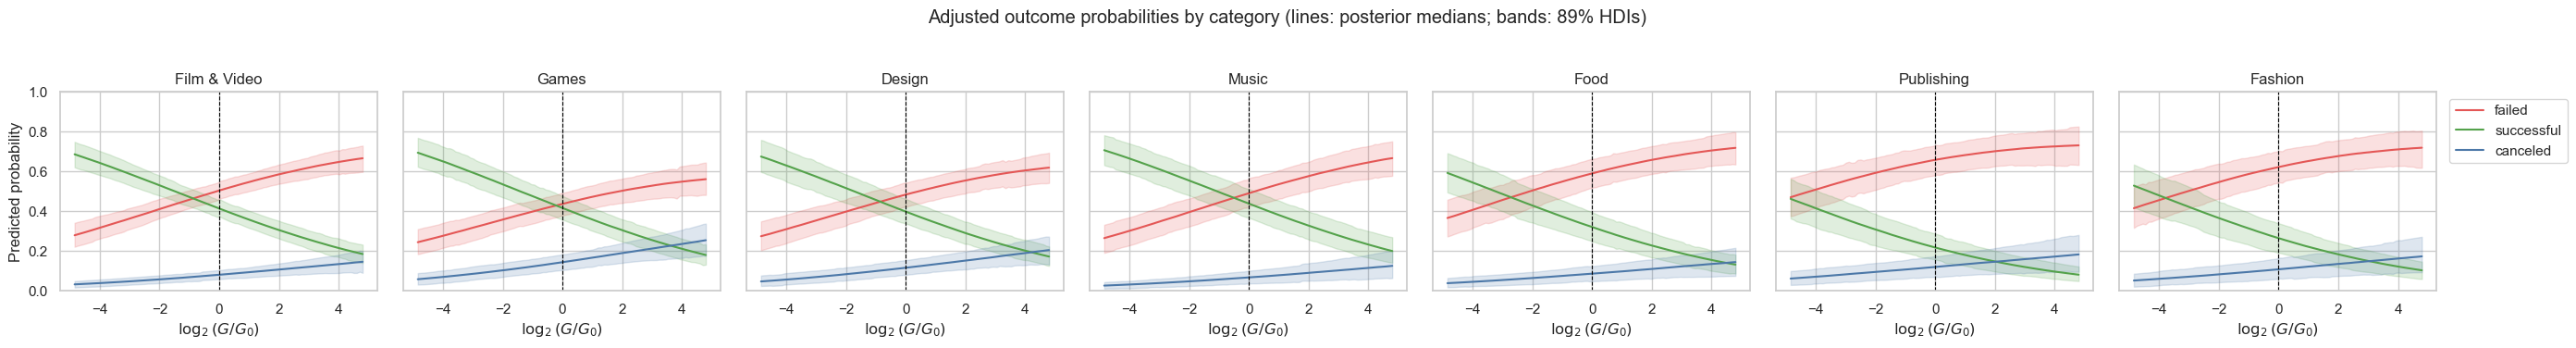

In [66]:
def columnwise_hdi(draws, hdi_prob=0.89):
    """Compute an HDI for every column of a (draw, value) array without 2-D ambiguity."""
    return np.asarray([az.hdi(draws[:, column], hdi_prob=hdi_prob) for column in range(draws.shape[1])])


def posterior_probabilities(x_values, category_index):
    """Return posterior probability draws, shape (draw, x, outcome)."""
    posterior = idata.posterior.stack(sample=("chain", "draw"))
    alpha_draws = posterior["alpha"].transpose("sample", "nonfailure_outcome").values
    beta_draws = posterior["beta_goal"].transpose("sample", "nonfailure_outcome").values
    category_draws = posterior["category_effect"].transpose(
        "sample", "category", "nonfailure_outcome"
    ).values[:, category_index, :]

    eta_nonfailure = (
        alpha_draws[:, None, :]
        + beta_draws[:, None, :] * np.asarray(x_values)[None, :, None]
        + category_draws[:, None, :]
    )
    eta = np.concatenate([np.zeros((*eta_nonfailure.shape[:2], 1)), eta_nonfailure], axis=-1)
    eta -= eta.max(axis=-1, keepdims=True)
    exp_eta = np.exp(eta)
    return exp_eta / exp_eta.sum(axis=-1, keepdims=True)

x_grid = np.linspace(analysis["log2_goal_ratio"].quantile(0.02), analysis["log2_goal_ratio"].quantile(0.98), 100)
fig, axes = plt.subplots(1, len(categories), figsize=(4 * len(categories), 3.6), sharey=True)
if len(categories) == 1:
    axes = [axes]

colors = {"failed": "#e45756", "successful": "#54a24b", "canceled": "#4c78a8"}
for category_index, (category, ax) in enumerate(zip(categories, axes)):
    probability_draws = posterior_probabilities(x_grid, category_index)
    for state_index, state in enumerate(states):
        interval = columnwise_hdi(probability_draws[:, :, state_index], hdi_prob=0.89)
        median = np.median(probability_draws[:, :, state_index], axis=0)
        ax.plot(x_grid, median, color=colors[state], label=state)
        ax.fill_between(x_grid, interval[:, 0], interval[:, 1], color=colors[state], alpha=0.18)
    ax.axvline(0, color="black", lw=0.8, ls="--")
    ax.set(title=category, xlabel=r"$\log_2(G/G_0)$", ylim=(0, 1))
axes[0].set_ylabel("Predicted probability")
axes[-1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("Adjusted outcome probabilities by category (lines: posterior medians; bands: 89% HDIs)", y=1.04)
plt.tight_layout()

## Evidence for the research question

The following compact table and statements translate the posterior into the estimand: the change in outcome odds relative to failure for a doubling of the goal, conditional on category. They also report the corresponding unadjusted estimate, so the consequence of treating category as a confounder is explicit rather than assumed.

In [ ]:
effect_evidence = []
for outcome in nonfailure_states:
    beta_draws = idata.posterior["beta_goal"].sel(nonfailure_outcome=outcome).values.ravel()
    odds_ratio_draws = np.exp(beta_draws)
    beta_hdi = az.hdi(beta_draws, hdi_prob=0.89)
    odds_hdi = az.hdi(odds_ratio_draws, hdi_prob=0.89)
    unadjusted_mean = unadjusted_idata.posterior["unadjusted_beta_goal"].sel(
        nonfailure_outcome=outcome
    ).values.mean()
    if beta_hdi[1] < 0:
        conclusion = "posterior supports lower odds when the goal doubles"
    elif beta_hdi[0] > 0:
        conclusion = "posterior supports higher odds when the goal doubles"
    else:
        conclusion = "direction remains uncertain at the 89% interval"
    effect_evidence.append({
        "outcome vs failed": outcome,
        "adjusted odds ratio, median": np.median(odds_ratio_draws),
        "adjusted odds-ratio 89% HDI": f"[{odds_hdi[0]:.2f}, {odds_hdi[1]:.2f}]",
        "unadjusted minus adjusted log-odds coefficient": unadjusted_mean - beta_draws.mean(),
        "interpretation": conclusion,
    })
effect_evidence = pd.DataFrame(effect_evidence).set_index("outcome vs failed")
display(effect_evidence)

baseline_probability = idata.posterior["p_at_G0_average_category"]
for outcome in states:
    values = baseline_probability.sel(outcome=outcome).values.ravel()
    interval = az.hdi(values, hdi_prob=0.89)
    print(f"At G0 in the average category, P({outcome}) has posterior median {np.median(values):.2f} "
          f"and 89% HDI [{interval[0]:.2f}, {interval[1]:.2f}].")

if ppc_summary["observed inside predictive interval"].all():
    print("All observed aggregate outcome counts are inside their 89% posterior-predictive intervals.")
else:
    print("At least one observed aggregate outcome count falls outside its 89% posterior-predictive interval.")

## Written discussion and future work

The `effect_evidence` table is the evidence for the research question. Its adjusted odds ratios describe the estimated change after a goal doubling **within category**, and its 89% HDIs communicate the uncertainty in that answer. The category-specific probability curves should be used with that table because odds ratios alone do not show the practical probability changes. The baseline probability statements make the three-state outcome—including failure—concrete at the geometric-mean goal.

Category is explicitly treated as a confounder: the adjusted model conditions on it, while the unadjusted-minus-adjusted column shows how the goal coefficient changes when category is omitted. The unadjusted coefficient is therefore an association across a changing mixture of categories, not the target category-adjusted causal effect. The posterior-predictive result is a check on whether the fitted model can reproduce the observed aggregate state distribution; agreement supports this limited aspect of fit, but does not establish the causal assumptions.

Future work should add pre-goal confounders such as creator history, campaign quality proxies, launch date, country/currency, and marketing reach, if they are measured before the outcome. A hierarchical category model would partially pool sparse categories; goal-by-category interactions and a nonlinear goal effect could test whether the effect is constant across categories and goal sizes. Finally, repeat posterior-predictive checks at the category level and use a held-out-time evaluation before relying on the model for prediction. Do not characterize the adjusted results as causal unless the DAG assumptions—especially no important unmeasured confounding within category and positivity—remain credible.